# Elegibilidad de mesas bajo FRTB: la prueba de atribución de P&L y la prueba retrospectiva de mesa (C13)

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 03 de este tema (pruebas retrospectivas y el semáforo)
- **Tiempo de lectura:** unos 40 minutos

**Pregunta:** De seis deficiencias plantadas en el modelo de riesgo de una mesa, ¿cuáles detecta la prueba de atribución de P&L de FRTB, cuáles deja pasar, y qué agrega la prueba retrospectiva a nivel de mesa?

## Objetivos

Al terminar este notebook puedes:

- enunciar los dos estadísticos de la prueba de atribución de ganancias y pérdidas (PLA), la correlación de Spearman y la distancia de Kolmogorov-Smirnov, calcularlos a mano y obtener los valores del motor;
- leer las zonas de la PLA y decir por qué el motor decide los límites sobre enteros;
- decir qué cuenta una prueba retrospectiva a nivel de mesa, cuáles son sus límites y cómo se trata un valor faltante;
- leer, para seis deficiencias plantadas en una mesa sintética, cuáles detecta la PLA, cuáles deja pasar y qué estadístico las detecta;
- dar el intervalo de 95 por ciento de una tasa de detección y decir qué puede y qué no puede afirmar una proporción de Monte Carlo sobre una verdad conocida.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas, imprimir las versiones con que corren y fijar las palabras que este notebook
# imprime para las luces del motor
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

El caso C13 pregunta qué concluye un validador cuando el modelo de riesgo de una mesa tiene una deficiencia conocida. Los datos son **sintéticos por diseño**: un generador produce el P&L hipotético (HPL, de la revaluación exacta de la mesa) y el P&L teórico del riesgo (RTPL, del modelo de riesgo) de una mesa de spread de dos factores, y se planta una deficiencia solo en el modelo de riesgo. Como la verdad es conocida, cada resultado se muestra junto a la deficiencia que debe detectar. No es el libro de ninguna mesa real y no dice nada sobre ningún banco.

- `data/derived/C13/models-generator.json`: el generador, sus parámetros, los umbrales de la PLA y los límites de la mesa.
- `data/derived/C13/<variante>.json` para seis variantes: `none` (sin deficiencia, el tamaño de la prueba), `missing-basis`, `stale-volatility`, `wrong-correlation`, `omitted-factor` y `time-misalignment`. Cada una guarda 1.000 replicaciones de 250 días resumidas (zonas, conteos de detección, conteos de excepciones) y **una replicación de ejemplo** con sus dos series de P&L de 250 días, la replicación que tiene el estadístico de Spearman mediano.
- `data/derived/C11/fx-2008.json` aporta datos reales para la prueba retrospectiva a nivel de mesa del paso 4.

El notebook recalcula la prueba sobre las seis replicaciones de ejemplo y lee los resúmenes de las 1.000. La celda siguiente carga los archivos e imprime las deficiencias plantadas.

In [2]:
# Cargar el documento del generador y las seis variantes del caso C13, e imprimir qué planta cada una y qué
# debería fallar
ROOT = Path("../../..").resolve()
VARIANTS = ("none", "missing-basis", "stale-volatility", "wrong-correlation", "omitted-factor", "time-misalignment")
C13 = ROOT / "data" / "derived" / "C13"
c13 = {v: json.loads((C13 / f"{v}.json").read_text(encoding="utf-8")) for v in VARIANTS}
generator = json.loads((C13 / "models-generator.json").read_text(encoding="utf-8"))["fit"]
INTENDED = {"none": "ninguna", "spearman": "Spearman", "ks": "KS", "both": "ambas", "either": "cualquiera"}

print("umbrales de la PLA:", {k: v for k, v in generator["pla_thresholds"].items() if k != "reference"})
print("límites de la mesa:", {d["alpha"]: d["limit_exceptions"] for d in generator["desk_limits"]})
for v in VARIANTS:
    known = c13[v]["outputs"]["known_deficiency"]
    params = [(p["name"], p["value"]) for p in known["parameters"]]
    print(f"{v:18s} plantada: {'sí' if known['planted'] else 'no':3s} | "
          f"debe fallar: {INTENDED.get(known['intended_to_fail'], known['intended_to_fail']):9s} | {params}")

umbrales de la PLA: {'spearman_green': 0.8, 'spearman_red': 0.7, 'ks_green': 0.09, 'ks_red': 0.12, 'ecdf_step': 0.004, 'window_days': 250}
límites de la mesa: {0.025: 30, 0.01: 12}
none               plantada: no  | debe fallar: ninguna   | []
missing-basis      plantada: sí  | debe fallar: Spearman  | [('basis_sd_share', 0.65)]
stale-volatility   plantada: sí  | debe fallar: KS        | [('vol_lag_days', 20.0)]
wrong-correlation  plantada: sí  | debe fallar: cualquiera | [('correlation_error', 0.3)]
omitted-factor     plantada: sí  | debe fallar: Spearman  | [('omitted_loading_share', 0.6)]
time-misalignment  plantada: sí  | debe fallar: Spearman  | [('lag_days', 1.0)]


## Método

### Paso 1: la prueba PLA

El enfoque de modelos internos de FRTB (Marco de Basilea MAR32.36 a MAR32.42) pregunta si el modelo de riesgo explica el P&L de la mesa. Sobre los 250 días más recientes compara el P&L teórico del riesgo con el hipotético de dos maneras. La **correlación de Spearman** es la correlación de Pearson de los rangos, de modo que pregunta si las dos series ordenan los días de igual manera:

$$r_S = \frac{\operatorname{cov}(R_{HPL}, R_{RTPL})}{\sigma_{R_{HPL}}\,\sigma_{R_{RTPL}}}$$

La distancia de **Kolmogorov-Smirnov** pregunta si las dos series tienen la misma distribución, con la función de distribución empírica $F(x) = 0{,}004\cdot\#\{\text{observaciones} \le x\}$:

$$KS = \sup_x \left| F_{RTPL}(x) - F_{HPL}(x) \right|$$

La zona es **verde** si $r_S > 0{,}80$ y $KS < 0{,}09$, **roja** si $r_S < 0{,}70$ o $KS > 0{,}12$, **ámbar** en otro caso. La roja deja a la mesa sin elegibilidad para el enfoque de modelos internos; la ámbar la mantiene con un recargo de capital. `pla_spearman`, `pla_ks`, `pla_zone` y `pla_test` del motor las implementan. La celda calcula los dos estadísticos a mano sobre la replicación de ejemplo de la variante `none`, con la correlación de rangos de SciPy y un conteo de los escalones de las dos funciones de distribución, y los imprime junto a los del motor.

In [3]:
# Spearman y Kolmogorov-Smirnov a mano sobre la replicación de ejemplo de la variante none, y la prueba PLA
# del motor
from riskvalidation.market.frtb import pla_ks, pla_spearman, pla_zone
from riskvalidation.validation.market import pla_test

example = c13["none"]["outputs"]["example"]
hpl, rtpl = np.array(example["hpl"]), np.array(example["rtpl"])
print(f"replicación {example['replication_index']}: {hpl.size} días")
print(f"HPL sd {hpl.std():.5f} | RTPL sd {rtpl.std():.5f}")
points = np.union1d(hpl, rtpl)
ecdf_hpl = np.searchsorted(np.sort(hpl), points, side="right") * 0.004
ecdf_rtpl = np.searchsorted(np.sort(rtpl), points, side="right") * 0.004
print(f"a mano: Spearman {stats.spearmanr(hpl, rtpl).statistic:.6f} | KS {np.max(np.abs(ecdf_rtpl - ecdf_hpl)):.3f}")
rho, ks = pla_spearman(hpl, rtpl), pla_ks(hpl, rtpl)
print(f"motor: Spearman {rho:.6f} | KS {ks:.3f} | zona {LIGHT[pla_zone(rho, ks)]}")
result = pla_test(hpl, rtpl, model_id="desk-risk-model")
print(f"pla_test: estadístico {result.statistic:.6f} | metric {result.metric:.3f} | {LIGHT[result.light.value]}")

replicación 9: 250 días
HPL sd 0.00529 | RTPL sd 0.00522
a mano: Spearman 0.992332 | KS 0.032
motor: Spearman 0.992332 | KS 0.032 | zona verde
pla_test: estadístico 0.992332 | metric 0.032 | verde


### Paso 2: límites decididos sobre enteros

Un límite de zona es una línea dura, y un estadístico que cae exactamente sobre ella no debe ser movido por el redondeo de punto flotante. La distancia KS es un conteo entero de escalones sobre 250, así que $KS < 0{,}09$ es $\text{brecha} \le 22$ y $KS > 0{,}12$ es $\text{brecha} \ge 31$. Los límites de Spearman 0,80 y 0,70 los decide `compare_spearman`, que trabaja con los rangos promedio duplicados como enteros y compara $S_{xy}^2$ con $\text{umbral}^2\,S_{xx}S_{yy}$ en aritmética racional exacta, y devuelve 1, 0 o -1 para encima, sobre y debajo. `pla_zone_exact` usa ambos y coincide con la regla de punto flotante `pla_zone` salvo donde un cociente en punto flotante caería sobre un límite. La celda imprime, para la replicación de ejemplo de cada variante, la brecha de escalones, la comparación con cada límite de Spearman y las dos reglas de zona.

In [4]:
# Para el ejemplo de cada variante: la brecha de escalones de KS, la comparación exacta con cada límite de
# Spearman y las dos reglas de zona
from riskvalidation.market.frtb import compare_spearman, pla_zone_exact

print(f"{'variant':18s} {'Spearman':>9s} {'KS':>6s} {'gap':>4s} {'vs 0.80':>8s} {'vs 0.70':>8s}  flotante exacta")
for v in VARIANTS:
    example = c13[v]["outputs"]["example"]
    h, r = np.array(example["hpl"]), np.array(example["rtpl"])
    rho, ks = pla_spearman(h, r), pla_ks(h, r)
    against = (compare_spearman(h, r, 0.80), compare_spearman(h, r, 0.70))
    float_zone, exact_zone = LIGHT[pla_zone(rho, ks)], LIGHT[pla_zone_exact(h, r)]
    gap = round(ks * 250)
    print(f"{v:18s} {rho:9.4f} {ks:6.3f} {gap:4d} {against[0]:8d} {against[1]:8d}  {float_zone:>8s} {exact_zone:>8s}")

variant             Spearman     KS  gap  vs 0.80  vs 0.70  flotante exacta
none                  0.9923  0.032    8        1        1     verde    verde
missing-basis         0.7107  0.104   26       -1        1     ámbar    ámbar
stale-volatility      0.9793  0.044   11        1        1     verde    verde
wrong-correlation     0.9865  0.144   36        1        1      rojo     rojo
omitted-factor        0.7749  0.080   20       -1        1     ámbar    ámbar
time-misalignment    -0.0065  0.028    7       -1       -1      rojo     rojo


### Paso 3: las seis replicaciones de ejemplo

Una replicación es un sorteo, pero muestra el mecanismo: cada deficiencia deja una marca distinta en los dos estadísticos. La celda corre `pla_test` sobre el ejemplo de cada variante y dibuja el P&L teórico del riesgo contra el hipotético, coloreado por la zona de la PLA. Una **base faltante** o un **factor omitido** agrega P&L que el modelo no puede ver, lo que debilita la correlación de rangos; un **desfase temporal** destruye por completo la correspondencia día a día; una **correlación errada** mantiene el orden de los días pero cambia la dispersión del P&L del modelo, algo que ve la distancia KS y no la correlación de Spearman; una **volatilidad desactualizada** cambia poco de ambas.

none               Spearman  0.9923 | KS 0.032 | zona verde
missing-basis      Spearman  0.7107 | KS 0.104 | zona ámbar
stale-volatility   Spearman  0.9793 | KS 0.044 | zona verde
wrong-correlation  Spearman  0.9865 | KS 0.144 | zona rojo
omitted-factor     Spearman  0.7749 | KS 0.080 | zona ámbar
time-misalignment  Spearman -0.0065 | KS 0.028 | zona rojo


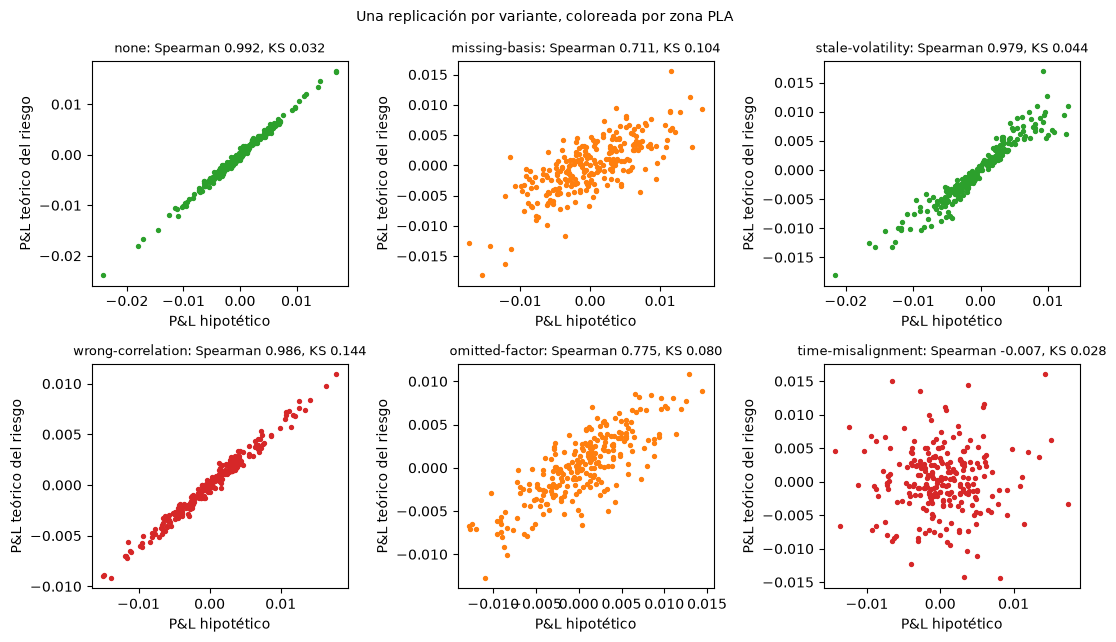

In [5]:
# Correr pla_test sobre la replicación de ejemplo de cada variante y dibujar el P&L teórico del riesgo
# contra el hipotético
colour = {"green": "tab:green", "amber": "tab:orange", "red": "tab:red"}
fig, axes = plt.subplots(2, 3, figsize=(11, 6.5))
for ax, v in zip(axes.ravel(), VARIANTS):
    example = c13[v]["outputs"]["example"]
    h, r = np.array(example["hpl"]), np.array(example["rtpl"])
    fresh = pla_test(h, r, model_id="desk-risk-model")
    ax.scatter(h, r, s=8, color=colour[fresh.light.value])
    ax.set_title(f"{v}: Spearman {fresh.statistic:.3f}, KS {fresh.metric:.3f}", fontsize=9)
    ax.set_xlabel("P&L hipotético")
    ax.set_ylabel("P&L teórico del riesgo")
    print(f"{v:18s} Spearman {fresh.statistic:7.4f} | KS {fresh.metric:.3f} | zona {LIGHT[fresh.light.value]}")
fig.suptitle("Una replicación por variante, coloreada por zona PLA", fontsize=10)
fig.tight_layout()
plt.show()

Cada panel dibuja el P&L del modelo de riesgo contra el verdadero, día a día. La mesa limpia queda sobre la diagonal (Spearman 0,9923, KS 0,032, verde). `missing-basis` (0,7107; 0,104) y `omitted-factor` (0,7749; 0,080) se dispersan alrededor de ella y caen en la zona ámbar por el lado de Spearman. `stale-volatility` (0,9793; 0,044) es casi indistinguible de la mesa limpia y se queda en verde. `wrong-correlation` conserva los rangos (Spearman 0,9865) pero su nube tiene la forma equivocada y su KS de 0,144 pasa el límite rojo, de modo que el color viene solo de KS. `time-misalignment` es una nube sin forma con un Spearman de -0,0065, roja. Una sola replicación muestra el mecanismo, no la frecuencia: el último paso cuenta con qué frecuencia ocurre cada patrón.

El desfase temporal es la deficiencia más fácil de reproducir a mano. La celda siguiente desplaza de 0 a 5 días el P&L teórico del riesgo del ejemplo `none` con `np.roll`, lo que convierte un modelo correcto en uno atrasado esa cantidad de días, y corre `pla_test` en cada desplazamiento. La figura dibuja la correlación de Spearman contra el desplazamiento con los límites de 0,80 y 0,70.

desplazamiento 0 días: Spearman  0.9923 | KS 0.032 | verde
desplazamiento 1 días: Spearman  0.0773 | KS 0.032 | rojo
desplazamiento 2 días: Spearman  0.0541 | KS 0.032 | rojo
desplazamiento 3 días: Spearman -0.0200 | KS 0.032 | rojo
desplazamiento 4 días: Spearman -0.0059 | KS 0.032 | rojo
desplazamiento 5 días: Spearman -0.0232 | KS 0.032 | rojo


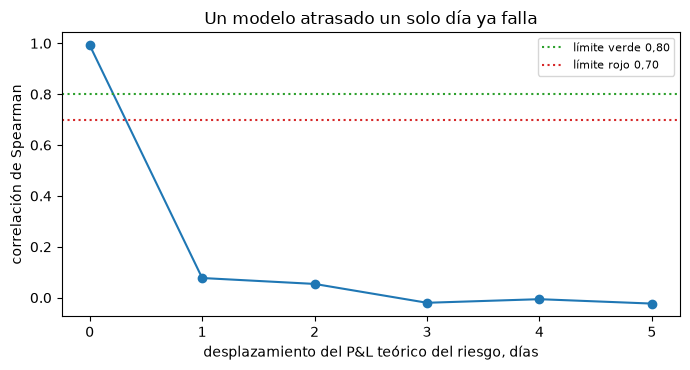

In [6]:
# Desplazar de 0 a 5 días el P&L teórico del riesgo del ejemplo none y correr la prueba PLA en cada
# desplazamiento
shifts = np.arange(6)
rows = [pla_test(hpl, np.roll(rtpl, int(s)), model_id="desk-risk-model") for s in shifts]
for s, row in zip(shifts, rows):
    print(f"desplazamiento {s} días: Spearman {row.statistic:7.4f} | KS {row.metric:.3f} | {LIGHT[row.light.value]}")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(shifts, [row.statistic for row in rows], marker="o")
ax.axhline(0.80, color="tab:green", linestyle=":", label="límite verde 0,80")
ax.axhline(0.70, color="tab:red", linestyle=":", label="límite rojo 0,70")
ax.set_xlabel("desplazamiento del P&L teórico del riesgo, días")
ax.set_ylabel("correlación de Spearman")
ax.set_title("Un modelo atrasado un solo día ya falla")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Un atraso de un día lleva la correlación de Spearman de 0,9923 a 0,0773 y la zona de verde a roja, y atrasos mayores no cambian el cuadro: los días de una serie de P&L casi no se relacionan con sus vecinos, así que un modelo atrasado un día no explica nada del día en que se lo puntúa. La distancia KS se queda en 0,032 en todos los desplazamientos, porque rotar la serie reordena los mismos valores y deja intacta su distribución. La figura muestra por qué la PLA necesita dos estadísticos: la distancia KS es ciega al orden y la correlación de Spearman es ciega a la forma de la distribución. No dice cuán atrasado podría estar un modelo real; la variante sintética usa un atraso de un día.

### Paso 4: la prueba retrospectiva a nivel de mesa

Además de la prueba PLA, una mesa de modelos internos debe someter a prueba retrospectiva su VaR a nivel de mesa (MAR32.18 a MAR32.19): sobre los 250 días más recientes cuenta los días en que la pérdida superó al VaR a un día de la mesa, y la mesa **pasa al enfoque estandarizado** si el conteo excede 12 al 99 por ciento o 30 al 97,5 por ciento. El motor tiene `desk_exception_limit(alpha)`, `desk_exceptions(loss, var, missing_as_exception)` y `desk_backtest(loss, var, alpha, basis)`. Una pérdida o un VaR faltante cuenta como excepción por defecto, ya que el marco trata un valor faltante como un valor atípico en la prueba retrospectiva de todo el banco y el motor mantiene la misma regla para una mesa tras una bandera. No hay ámbar: la luz es roja sobre el límite y verde en otro caso.

Las mesas sintéticas de C13 versionan sus conteos de excepciones pero no las series de pérdida y VaR, así que este paso usa datos reales: la posición en euros de `fx-2008` como una mesa de una sola posición, su pérdida realizada y el VaR `ewma` versionado para los últimos 250 de sus 251 días. La celda muestra el conteo, el límite y la luz en ambos niveles, y luego deja en blanco dos días para mostrar el tratamiento de los valores faltantes.

In [7]:
# Prueba retrospectiva de mesa de la posición en euros (una mesa de una posición): excepciones en los
# últimos 250 días frente al límite
from riskvalidation.market.frtb import desk_exception_limit, desk_exceptions
from riskvalidation.validation.market import desk_backtest

fx = json.loads((ROOT / "data" / "derived" / "C11" / "fx-2008.json").read_text(encoding="utf-8"))
fx_loss = np.array(fx["outputs"]["grid"]["realised_loss"]["loss"])
ewma = {m["model_id"]: m for m in fx["outputs"]["models"]}["ewma"]
for level in ewma["by_level"]:
    alpha = level["alpha"]
    outcome = desk_backtest(fx_loss, np.array(level["var"]), alpha, model_id="ewma", basis="HPL")
    print(f"alfa {alpha}: excepciones en los últimos 250 días {int(outcome.statistic)} | "
          f"límite {int(outcome.metric)} | {LIGHT[outcome.light.value]}")

var = np.array(ewma["by_level"][0]["var"])
blanked = fx_loss.copy()
blanked[[100, 101]] = np.nan
print("límites:", {a: desk_exception_limit(a) for a in (0.01, 0.025)})
print(f"faltantes contados como excepciones: {desk_exceptions(blanked[-250:], var[-250:])}")
print(f"faltantes ignorados: {desk_exceptions(blanked[-250:], var[-250:], missing_as_exception=False)}")
print(f"sin faltantes: {desk_exceptions(fx_loss[-250:], var[-250:])}")

alfa 0.01: excepciones en los últimos 250 días 3 | límite 12 | verde
alfa 0.025: excepciones en los últimos 250 días 8 | límite 30 | verde
límites: {0.01: 12, 0.025: 30}
faltantes contados como excepciones: 5
faltantes ignorados: 3
sin faltantes: 3


Tratando la posición en euros de `fx-2008` como una mesa de una sola posición, el VaR de EWMA tiene 3 excepciones en los últimos 250 días al 99 por ciento contra un límite de 12, y 8 al 97,5 por ciento contra un límite de 30: verde en ambos niveles, con holgura. Las tres últimas líneas muestran el tratamiento de un valor faltante: con dos días de P&L faltante el conteo es 5 cuando un valor faltante cuenta como excepción, la regla por defecto del motor, y 3 cuando se ignora, igual que sin valores faltantes. La prueba de mesa no tiene ámbar y cuenta solo el número de días sobre el VaR, sin mirar su tamaño, de modo que no puede decir nada sobre una mesa cuyo modelo está errado en el centro de la distribución.

### Paso 5: con qué frecuencia se detecta cada deficiencia

Lo que un validador necesita saber no es si la prueba detectó una replicación sino con qué **frecuencia**. Cada variante corrió 1.000 replicaciones, y el artefacto registra cuántas fueron ámbar o rojas en la PLA (la deficiencia está **detectada**), cuántas fueron rojas, cuántas superaron el límite de la mesa al 99 por ciento y qué estadístico las marcó. Para la variante sin deficiencia la misma proporción es la **tasa de falsa alarma** (el tamaño de la prueba). Una proporción $\hat p$ de $n$ replicaciones lleva un error de Monte Carlo cuyo error estándar es cero en 0 y 1, así que el intervalo usado es el de puntaje de Wilson, que queda dentro de [0, 1] y no es degenerado en los bordes (Brown, Cai y DasGupta, 2001). La celda lee los conteos de cada variante y pide a `wilson_interval` del motor el intervalo de 95 por ciento de la proporción detectada; la figura dibuja las tres proporciones.

variant            detectadas  rojas  mesa>12
none                    0.000  0.000    0.000
                   marcadas por Spearman 0, KS 0
                   intervalo de 95%: 0.0000 a 0.0038
missing-basis           0.960  0.575    0.565
                   marcadas por Spearman 919, KS 867
                   intervalo de 95%: 0.9460 a 0.9705
stale-volatility        0.000  0.000    0.005
                   marcadas por Spearman 0, KS 0
                   intervalo de 95%: 0.0000 a 0.0038
wrong-correlation       1.000  0.913    0.953
                   marcadas por Spearman 0, KS 1000
                   intervalo de 95%: 0.9962 a 1.0000
omitted-factor          0.901  0.043    0.064
                   marcadas por Spearman 805, KS 448
                   intervalo de 95%: 0.8809 a 0.9180
time-misalignment       1.000  1.000    0.000
                   marcadas por Spearman 1000, KS 0
                   intervalo de 95%: 0.9962 a 1.0000


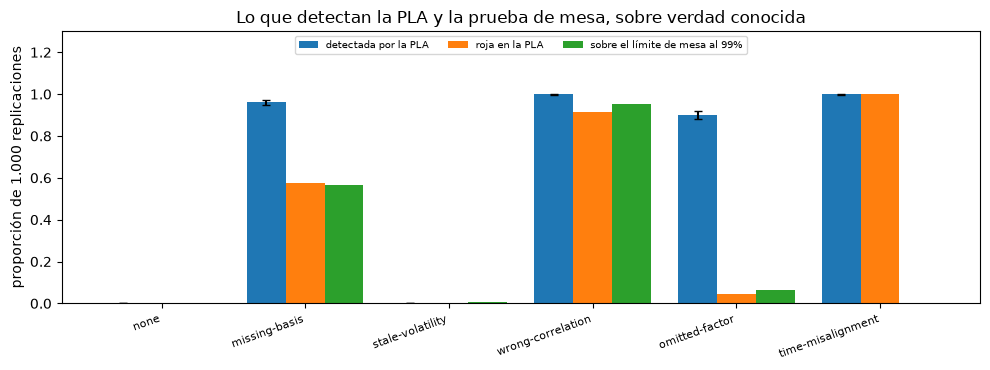

In [8]:
# Proporciones de detección de las 1.000 replicaciones por variante con el intervalo de Wilson del motor, y
# las proporciones dibujadas
from riskvalidation.harness.rates import wilson_interval

det = {v: c13[v]["outputs"]["detection"] for v in VARIANTS}
caught = np.array([det[v]["share_amber_or_red"] for v in VARIANTS])
red = np.array([det[v]["share_red"] for v in VARIANTS])
desk = np.array([c13[v]["impact"]["share_desk_over_limit_99"]["value"] for v in VARIANTS])
low, high = np.array([wilson_interval(det[v]["n_amber_or_red"], det[v]["n_replications"]) for v in VARIANTS]).T
print(f"{'variant':18s} {'detectadas':>10s} {'rojas':>6s} {'mesa>12':>8s}")
for i, v in enumerate(VARIANTS):
    by = det[v]["by_test"]
    print(f"{v:18s} {caught[i]:10.3f} {red[i]:6.3f} {desk[i]:8.3f}")
    print(f"{'':18s} marcadas por Spearman {by['spearman_flagged']}, KS {by['ks_flagged']}")
    print(f"{'':18s} intervalo de 95%: {low[i]:.4f} a {high[i]:.4f}")

x = np.arange(len(VARIANTS))
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(x - 0.27, caught, 0.27, yerr=[caught - low, high - caught], capsize=3, label="detectada por la PLA")
ax.bar(x, red, 0.27, label="roja en la PLA")
ax.bar(x + 0.27, desk, 0.27, label="sobre el límite de mesa al 99%")
ax.set_xticks(x, VARIANTS, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("proporción de 1.000 replicaciones")
ax.set_title("Lo que detectan la PLA y la prueba de mesa, sobre verdad conocida")
ax.set_ylim(0, 1.3)
ax.legend(fontsize=7, ncol=3, loc="upper center")
fig.tight_layout()
plt.show()

Las barras azules son la proporción de las 1.000 replicaciones que la PLA detectó (ámbar o roja), con el intervalo de Wilson de 95 por ciento como tapa negra. Sin deficiencia la PLA es ámbar o roja en 0,000 de las replicaciones y el límite superior del intervalo es 0,0038: casi nunca acusa a un modelo correcto en este generador. `time-misalignment` y `wrong-correlation` se detectan en todas las replicaciones (intervalo de 0,9962 a 1,0000), `missing-basis` en 0,960 (0,9460 a 0,9705) y `omitted-factor` en 0,901 (0,8809 a 0,9180), pero esta última es roja en solo 0,043 de ellas. `stale-volatility` se detecta en 0,000 de las replicaciones, de modo que un atraso de 20 días en la volatilidad de entrada no se ve en la comparación de P&L. Las barras naranja y verde muestran que la prueba de mesa detecta un subconjunto distinto: 0,953 de `wrong-correlation` y ninguna de `time-misalignment`. Una proporción sobre un generador con verdad conocida dice cómo se comporta la prueba sobre estas deficiencias; no dice con qué frecuencia una mesa real tiene una.

## Resultados

**Respuesta:** La PLA detecta cuatro de las cinco deficiencias plantadas casi siempre y deja pasar la quinta por completo. El desfase temporal y la correlación errada se detectan en 1,000 de las replicaciones (intervalo de 0,9962 a 1,0000), la base faltante en 0,960 y el factor omitido en 0,901, sin falsa alarma sobre la mesa limpia (0,000 detectadas, límite superior 0,0038). La volatilidad desactualizada se detecta en 0,000 de ellas, aunque el archivo la marca como destinada a fallar en KS, y la prueba retrospectiva de mesa detecta un subconjunto distinto: 0,953 de las replicaciones de correlación errada y 0,000 de las de desfase temporal.

- **Los estadísticos a mano.** En la replicación de ejemplo de la variante `none` (replicación 9) la correlación de Spearman es 0,992332 y la distancia KS 0,032 a mano y con el motor, y la zona es verde.
- **Límites sobre enteros.** `missing-basis` (Spearman 0,7107, brecha 26) y `omitted-factor` (0,7749, brecha 20) son ámbar porque su Spearman queda entre 0,70 y 0,80 (comparación -1 frente a 0,80, +1 frente a 0,70). `wrong-correlation` tiene un Spearman de 0,9865 y una brecha de 36, pasado el límite rojo de 31, de modo que es roja solo por KS. `time-misalignment` tiene un Spearman de -0,0065 y es roja. La regla flotante y la exacta coinciden en las seis.
- **Un atraso de un día.** Desplazar un día el P&L teórico del riesgo del ejemplo limpio lleva la correlación de Spearman de 0,9923 a 0,0773 y la zona a roja, mientras la distancia KS se queda en 0,032.
- **La prueba retrospectiva de mesa.** Tratando la posición en euros de `fx-2008` como una mesa de una posición, el VaR de `ewma` tiene 3 excepciones en los últimos 250 días a 0,01 (límite 12) y 8 a 0,025 (límite 30): verde en ambos. Con dos días de P&L faltante el conteo es 5 cuando los valores faltantes cuentan como excepciones, la regla por defecto, y 3 cuando se ignoran.
- **Qué se detecta.** `missing-basis` la marca Spearman en 919 replicaciones y KS en 867 (roja en 0,575); `omitted-factor` Spearman en 805 y KS en 448 (roja en solo 0,043); `wrong-correlation` KS en 1000 y nunca Spearman; `time-misalignment` Spearman en 1000 y nunca KS.
- **El intervalo.** El intervalo de Wilson de una proporción es el de una proporción de Monte Carlo sobre un generador con verdad conocida, por ejemplo 0,9460 a 0,9705 para `missing-basis`. No dice nada sobre con qué frecuencia una mesa real tiene una de estas deficiencias.

Lo que este notebook no muestra: las consecuencias de capital de una mesa ámbar o roja (recargo o enfoque estandarizado), que pertenecen a las calculadoras regulatorias.

## Resumen

- La prueba PLA tiene dos estadísticos que ven cosas distintas: la correlación de Spearman ve si las dos series de P&L ordenan los días de igual manera, la distancia KS si tienen la misma distribución. Una deficiencia puede romper uno y dejar intacto el otro, así que la zona conjunta toma el peor de los dos.
- Los límites de zona se deciden sobre enteros (una brecha de escalones para KS, aritmética racional exacta para Spearman), de modo que un valor sobre un límite nunca lo mueve el redondeo.
- Un modelo atrasado un día tiene una correlación de Spearman cercana a cero y la misma distancia KS que uno correcto, el ejemplo más claro de por qué se necesitan ambos estadísticos.
- La prueba retrospectiva de mesa cuenta excepciones frente a un límite (12 al 99 por ciento, 30 al 97,5 por ciento) sin ámbar, y un valor faltante cuenta como excepción por defecto.
- En una mesa sintética con una deficiencia plantada la verdad es conocida, así que la prueba se puede juzgar por su tasa de detección y su tasa de falsa alarma, cada una con un intervalo. La PLA detecta algunas deficiencias casi siempre y otras nunca, y la prueba de mesa detecta un subconjunto distinto.

**Qué probar después.** Cambia el atraso de la celda de desplazamiento por una fracción de la serie mezclando `rtpl` con una copia rotada de sí misma y encuentra la mezcla en que la zona pasa a ámbar; luego lee la descripción del generador en el SDD.

## Referencias

- Comité de Supervisión Bancaria de Basilea, Marco de Basilea, MAR32.18 a MAR32.19 (backtesting a nivel de mesa) y MAR32.36 a MAR32.42 (la prueba de atribución de pérdidas y ganancias), tal como los implementa `riskvalidation.market.frtb` del motor.
- Comité de Supervisión Bancaria de Basilea (1996), Supervisory framework for the use of backtesting in conjunction with the internal models approach to market risk capital requirements. https://www.bis.org/publ/bcbs22.htm
- Brown, L. D., Cai, T. T. y DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286